In [4]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [5]:
from IPython.display import display, Markdown, Math, HTML

import numpy as np
from scipy.constants import epsilon_0, c, hbar
from pyGDM2 import fields

from optomechanics_levitation import particle_properties, rotate_particle, evaluate_incident_field, evaluate_internal_field, evaluate_far_field, force_spectral_density, torque_spectral_density

In [6]:
## PARTICLE PROPERTIES
long_axis = 100.0; long_radius = long_axis / 2.0; aspect_ratio = 2.0; short_radius = long_radius / aspect_ratio # [nm]
wavelength = 1550.0 # [nm]
intensity = 1.0e9 # [W/m^2]

# Discretization step
if aspect_ratio == 2.0:
    mesh_divisions = 35.0
else:
    mesh_divisions = 65.0
step = long_axis / mesh_divisions # [nm]

# x-oriented ellipsoidal particle
ellipsoidal_particle = particle_properties(particle_type="spheroid", material_name="sio2", step_nm=step, mesh="cube",
                                           center=True, R1=long_radius / step - 0.2, R2=short_radius / step - 0.2, R3=short_radius / step - 0.2)

# INTERACTION PARAMETERS
far_field_radius = 1e6 # [nm]

# Information patterns of recoil-heating torque

The **incident** surface shows the total torque spectral density after integrating over all outgoing directions, as a function of the direction of one incident beam. The **scattered** surface shows the torque spectral density **per outgoing solid angle**, for one fixed incident direction. These are different angular quantities and have different units. Each pair of surfaces is drawn separately for RCP ($\sigma=+1$) and LCP ($\sigma=-1$).

The particle, wavelength and intensity above are unchanged. Both beams are focused or referenced at the particle centre and have the same field intensity there. The fixed incident direction for the scattered surface is $+\hat{\mathbf z}$; the torque component is about $y$. Each incident direction in the scan represents a separate illumination.

In [7]:
## SHARED ANGULAR GRID AND SETTINGS
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import cm, colors
from scipy.interpolate import RegularGridInterpolator
from tqdm.auto import tqdm

from optomechanics_levitation import hermite_gauss_00
from optomechanics_levitation.observables import _angular_spectrum_from_field, _field_from_angular_spectrum

environment = {"eps1": 1.0, "eps2": 1.0, "eps3": 1.0, "spacing": 0.0}
E0 = np.sqrt(2 * intensity / (epsilon_0 * c))
particle_center_nm = np.mean(ellipsoidal_particle["geometry_nm"], axis=0)
reference_direction = np.array([0.0, 0.0, 1.0])
helicities = (+1, -1)

# 12 x 24 incident directions per helicity (vs. 8 x 16 in Torque Components Distribution).
# The equal-area cos(theta) grid is physically sampled; interpolation below is display only.
n_cos_theta = 12
n_azimuth = 24
cos_theta = -1 + (np.arange(n_cos_theta) + 0.5) * 2 / n_cos_theta
azimuth = (np.arange(n_azimuth) + 0.5) * 2 * np.pi / n_azimuth
directions = np.array([
    [[np.sqrt(1 - u**2) * np.cos(phi), np.sqrt(1 - u**2) * np.sin(phi), u]
     for phi in azimuth] for u in cos_theta
])

# Use 64 x 64 for the incident scan and 64 x 128 for fixed outgoing patterns.
torque_kwargs = dict(
    torque_axis="y", radius_wavelengths=far_field_radius / wavelength,
    n_theta=64, n_phi=64,
)
outgoing_torque_kwargs = dict(torque_kwargs, n_phi=128)
pattern_signature = ("homogeneous_far_field_v1", n_cos_theta, n_azimuth,
                     torque_kwargs["n_theta"], torque_kwargs["n_phi"], outgoing_torque_kwargs["n_phi"])
SAVE_CSV = True
shared_interaction = {"prepared": None}

def beam_frame(direction):
    """Columns are a right-handed local (x, y, propagation) basis in lab coordinates."""
    k = np.asarray(direction, dtype=float)
    k = k / np.linalg.norm(k)
    reference = np.array([1.0, 0.0, 0.0]) if abs(k[0]) < 0.9 else np.array([0.0, 1.0, 0.0])
    x = reference - np.dot(reference, k) * k
    x = x / np.linalg.norm(x)
    return np.column_stack((x, np.cross(k, x), k))

def plane_wave_direction(pos, env_dict, wavelength, direction, helicity, returnField="E"):
    frame = beam_frame(direction)
    k = frame[:, 2]
    polarization = (frame[:, 0] + 1j * helicity * frame[:, 1]) / np.sqrt(2)
    electric = np.exp(2j * np.pi / wavelength * (np.asarray(pos) @ k))[:, None] * polarization
    return electric if returnField.lower() == "e" else np.cross(k, electric) / c

def plane_wave_parameters(direction, helicity):
    return dict(wavelength_nm=wavelength, environment=environment, amplitude_v_per_m=E0,
                direction=tuple(direction), helicity=helicity)

/home/sgb1u26/.conda/envs/optomechanics-levitation/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [8]:
## SHARED SCAN, TABLE, PLOT AND CSV HELPERS
def empty_pattern_result():
    return {
        "signature": pattern_signature,
        "torque_map": {name: np.full((2, n_cos_theta, n_azimuth), np.nan)
                       for name in ("total", "spin", "orbital", "mixed")},
        "outgoing": {},
    }

def solve_beam(field_generator, incident_parameters):
    incident_field = evaluate_incident_field(
        field_generator=field_generator,
        positions_nm=ellipsoidal_particle["geometry_nm"], field="E", **incident_parameters)
    prepared = shared_interaction["prepared"]
    interaction = evaluate_internal_field(
        particle=ellipsoidal_particle if prepared is None else None,
        incident_electric_field=incident_field, wavelength_nm=wavelength,
        environment=environment, prepared_interaction=prepared)
    shared_interaction["prepared"] = interaction["prepared_interaction"]
    return interaction

def run_angular_scan(result, label, field_generator, parameter_factory, spectrum_factory=None):
    torque_map = result["torque_map"]
    completed = int(np.isfinite(torque_map["total"]).sum()) + len(result["outgoing"])
    total_cases = torque_map["total"].size + len(helicities)
    with tqdm(total=total_cases, initial=completed, desc=label, unit="beam") as progress:
        for h, helicity in enumerate(helicities):
            for i in range(n_cos_theta):
                for j in range(n_azimuth):
                    if np.isfinite(torque_map["total"][h, i, j]):
                        continue
                    direction = directions[i, j]
                    parameters = parameter_factory(direction, helicity)
                    interaction = solve_beam(field_generator, parameters)
                    spectrum = None if spectrum_factory is None else spectrum_factory(direction, helicity)
                    terms = torque_spectral_density(
                        interaction, field_generator, parameters,
                        incident_spectrum=spectrum, **torque_kwargs)
                    for name, value in zip(("total", "spin", "orbital", "mixed"), terms):
                        torque_map[name][h, i, j] = value / (2 * np.pi)
                    progress.update(1)

            if helicity not in result["outgoing"]:
                parameters = parameter_factory(reference_direction, helicity)
                interaction = solve_beam(field_generator, parameters)
                spectrum = None if spectrum_factory is None else spectrum_factory(reference_direction, helicity)
                totals, angular = torque_spectral_density(
                    interaction, field_generator, parameters, incident_spectrum=spectrum,
                    return_angular=True, **outgoing_torque_kwargs)
                absolute_tolerance = 1e-12 * max(abs(totals[1]), abs(totals[2])) / (2 * np.pi)
                for name, value in zip(("total", "spin", "orbital", "mixed"), totals):
                    integrated = np.sum(angular[name] * angular["domega"])
                    if not np.isclose(integrated, value / (2 * np.pi),
                                      rtol=1e-8, atol=absolute_tolerance):
                        raise RuntimeError(f"Outgoing {name} density does not integrate to its total")
                result["outgoing"][helicity] = angular
                progress.update(1)

def percentages(torque_map):
    spin = torque_map["spin"]
    orbital = torque_map["orbital"]
    correlation = 2 * torque_map["mixed"]
    reference = spin + orbital
    terms = {"spin": spin, "orbital": orbital,
             "reduction": np.maximum(-correlation, 0),
             "increase": np.maximum(correlation, 0)}
    fractions = {}
    for name, term in terms.items():
        fraction = np.full_like(reference, np.nan)
        np.divide(100 * term, reference, out=fraction, where=reference > 0)
        fractions[name] = fraction
    return reference, terms, fractions

def sci_notation(value, decimals=2):
    mantissa, exponent = f"{value:.{decimals}e}".split("e")
    return rf"{mantissa} \times 10^{{{int(exponent)}}}"

def show_summary(result):
    torque_map = result["torque_map"]
    reference, terms, fractions = percentages(torque_map)
    total_map = torque_map["total"]
    display(Markdown(
        rf"Directions completed: **{np.isfinite(total_map).sum()}/{total_map.size}**. "
        r"The reference is $S_0=S_{\mathrm{spin}}+S_{\mathrm{orbital}}$. "
        r"Spin and orbital shares add to $100\%$; correlation reduction and increase "
        r"are separate percentages of $S_0$, not additional shares of the total noise."
    ))
    rows = [
        r"| Polarization | Mean $S_{\tau\tau}$ [$\mathrm{N}^2\mathrm{m}^2/\mathrm{Hz}$] | Spin share | Orbital share | Correlation reduction | Correlation increase | Directions in histograms |",
        "|---|---:|---:|---:|---:|---:|---:|",
    ]
    for h, label in enumerate((r"RCP ($\sigma=+1$)", r"LCP ($\sigma=-1$)")):
        mean_total = np.nanmean(total_map[h])
        mean_reference = np.nanmean(reference[h])
        shares = [100 * np.nanmean(terms[name][h]) / mean_reference
                  for name in ("spin", "orbital", "reduction", "increase")]
        valid = np.isfinite(fractions["spin"][h]).sum()
        rows.append(
            rf"| {label} | ${sci_notation(mean_total)}$ | ${shares[0]:.2f}\%$ | ${shares[1]:.2f}\%$ "
            rf"| ${shares[2]:.2f}\%$ | ${shares[3]:.2f}\%$ | {valid}/{n_cos_theta * n_azimuth} |"
        )
    display(Markdown("\n".join(rows)))

def interpolated_surface(values, u, phi, basis, n_u=65, n_phi=129):
    """Smooth only the drawn surface; keep the physical samples unchanged."""
    u_order = np.argsort(u)
    phi_order = np.argsort(phi)
    u = np.asarray(u)[u_order]
    phi = np.asarray(phi)[phi_order]
    values = np.asarray(values)[np.ix_(u_order, phi_order)]
    u_nodes = np.r_[-1.0, u, 1.0]
    values = np.vstack((np.full((1, len(phi)), values[0].mean()),
                        values, np.full((1, len(phi)), values[-1].mean())))
    phi_nodes = np.r_[phi[-1] - 2 * np.pi, phi, phi[0] + 2 * np.pi]
    values = np.column_stack((values[:, -1], values, values[:, 0]))
    interpolator = RegularGridInterpolator((u_nodes, phi_nodes), values)
    U, P = np.meshgrid(np.linspace(-1, 1, n_u), np.linspace(0, 2 * np.pi, n_phi), indexing="ij")
    samples = np.column_stack((U.ravel(), P.ravel()))
    smooth_values = interpolator(samples).reshape(U.shape)
    local_directions = np.stack((np.sqrt(1 - U**2) * np.cos(P),
                                 np.sqrt(1 - U**2) * np.sin(P), U), axis=-1)
    return local_directions @ basis, smooth_values

def draw_surface(ax, directions_grid, values, scale, title, unit_label):
    scale = max(float(scale), np.finfo(float).tiny)
    shown = np.clip(values, 0, None)
    radius = shown / scale
    xyz = directions_grid * radius[..., None]
    norm = colors.Normalize(vmin=0, vmax=scale)
    ax.plot_surface(xyz[..., 0], xyz[..., 1], xyz[..., 2],
                    facecolors=cm.viridis(norm(shown)), linewidth=0,
                    antialiased=True, shade=False, rstride=1, cstride=1)
    ax.set(xlim=(-1.05, 1.05), ylim=(-1.05, 1.05), zlim=(-1.05, 1.05),
           xlabel="$x$", ylabel="$y$", zlabel="$z$", title=title)
    ax.set_box_aspect((1, 1, 1))
    ax.view_init(elev=25, azim=40)
    return cm.ScalarMappable(norm=norm, cmap="viridis"), unit_label

def plot_pattern_pair(result, beam_name, helicity):
    h = helicities.index(helicity)
    angular = result["outgoing"][helicity]
    input_scale = np.nanmax(result["torque_map"]["total"])
    output_scale = max(np.nanmax(result["outgoing"][sigma]["total"]) for sigma in helicities)

    incident_grid, incident_values = interpolated_surface(
        result["torque_map"]["total"][h], cos_theta, azimuth, np.eye(3))
    n_theta_out, n_phi_out = angular["total"].shape
    theta_out = (np.arange(n_theta_out) + 0.5) * np.pi / n_theta_out
    phi_out = np.arange(n_phi_out) * 2 * np.pi / n_phi_out
    # _angular_surface uses this basis when torque_axis='y'.
    outgoing_basis = np.eye(3)[[2, 0, 1]]
    outgoing_grid, outgoing_values = interpolated_surface(
        angular["total"], np.cos(theta_out), phi_out, outgoing_basis)

    fig = plt.figure(figsize=(13, 6), constrained_layout=True)
    axes = [fig.add_subplot(1, 2, index + 1, projection="3d") for index in range(2)]
    color_mappable, label = draw_surface(
        axes[0], incident_grid, incident_values, input_scale,
        "Incident direction: integrated $S_{\\tau\\tau}$", r"$S_{\tau\tau}$ [N$^2$ m$^2$/Hz]")
    fig.colorbar(color_mappable, ax=axes[0], shrink=0.60, pad=0.08, label=label)
    color_mappable, label = draw_surface(
        axes[1], outgoing_grid, outgoing_values, output_scale,
        "Scattered direction: $dS_{\\tau\\tau}/d\\Omega$",
        r"$dS_{\tau\tau}/d\Omega$ [N$^2$ m$^2$/(Hz sr)]")
    fig.colorbar(color_mappable, ax=axes[1], shrink=0.60, pad=0.08, label=label)
    polarization = "RCP" if helicity == 1 else "LCP"
    fig.suptitle(f"{beam_name}: {polarization} ($\\sigma={helicity:+d}$)")
    plt.show()

def save_pattern_csv(result, filename):
    """One CSV per beam, with 'surface' and 'value_units' distinguishing the two maps."""
    reference, terms, fractions = percentages(result["torque_map"])
    rows = []
    for h, helicity in enumerate(helicities):
        polarization = "RCP" if helicity == 1 else "LCP"
        for i in range(n_cos_theta):
            for j in range(n_azimuth):
                direction = directions[i, j]
                rows.append({
                    "surface": "incident", "value_units": "N2 m2/Hz",
                    "helicity": helicity, "polarization": polarization,
                    "theta_deg": np.degrees(np.arccos(direction[2])),
                    "phi_deg": np.degrees(np.arctan2(direction[1], direction[0]) % (2 * np.pi)),
                    "direction_x": direction[0], "direction_y": direction[1], "direction_z": direction[2],
                    "incident_x": direction[0], "incident_y": direction[1], "incident_z": direction[2],
                    "solid_angle_weight_sr": 4 * np.pi / (n_cos_theta * n_azimuth),
                    "spin": result["torque_map"]["spin"][h, i, j],
                    "orbital": result["torque_map"]["orbital"][h, i, j],
                    "mixed": result["torque_map"]["mixed"][h, i, j],
                    "correlation": 2 * result["torque_map"]["mixed"][h, i, j],
                    "total": result["torque_map"]["total"][h, i, j],
                    "spin_pct_S0": fractions["spin"][h, i, j],
                    "orbital_pct_S0": fractions["orbital"][h, i, j],
                    "correlation_reduction_pct_S0": fractions["reduction"][h, i, j],
                    "correlation_increase_pct_S0": fractions["increase"][h, i, j],
                })

        angular = result["outgoing"][helicity]
        for i, j in np.ndindex(angular["total"].shape):
            direction = angular["directions"][i, j]
            spin = angular["spin"][i, j]
            orbital = angular["orbital"][i, j]
            correlation = angular["correlation"][i, j]
            reference_value = spin + orbital
            rows.append({
                "surface": "scattered", "value_units": "N2 m2/(Hz sr)",
                "helicity": helicity, "polarization": polarization,
                "theta_deg": np.degrees(np.arccos(np.clip(direction[2], -1, 1))),
                "phi_deg": np.degrees(np.arctan2(direction[1], direction[0]) % (2 * np.pi)),
                "direction_x": direction[0], "direction_y": direction[1], "direction_z": direction[2],
                "incident_x": reference_direction[0], "incident_y": reference_direction[1],
                "incident_z": reference_direction[2],
                "solid_angle_weight_sr": angular["domega"][i, j],
                "spin": spin, "orbital": orbital, "mixed": angular["mixed"][i, j],
                "correlation": correlation, "total": angular["total"][i, j],
                "spin_pct_S0": 100 * spin / reference_value if reference_value > 0 else np.nan,
                "orbital_pct_S0": 100 * orbital / reference_value if reference_value > 0 else np.nan,
                "correlation_reduction_pct_S0": 100 * max(-correlation, 0) / reference_value if reference_value > 0 else np.nan,
                "correlation_increase_pct_S0": 100 * max(correlation, 0) / reference_value if reference_value > 0 else np.nan,
            })

    root = next(base for base in (Path.cwd(), *Path.cwd().parents)
                if (base / "src" / "optomechanics_levitation").is_dir())
    output_dir = root / "outputs" / "recoil_heatings_results"
    output_dir.mkdir(parents=True, exist_ok=True)
    output_path = output_dir / filename
    pd.DataFrame(rows).to_csv(output_path, index=False, float_format="%.16e")
    display(Markdown(f"Saved **{len(rows)} rows** to `{output_path}`"))
    return output_path

## Plane wave

The scan evaluates both helicities on the same 12 × 24 equal-area incidence grid. The additional $+\hat{\mathbf z}$ calculation supplies the outgoing directional density for each helicity. The table has the same columns, units and share convention as *Torque Components Distribution*.

In [9]:
## PLANE-WAVE ANGULAR SCAN (re-run this cell to resume an interrupted scan)
if "plane_wave_result" not in globals() or plane_wave_result.get("signature") != pattern_signature:
    plane_wave_result = empty_pattern_result()
run_angular_scan(plane_wave_result, "Plane wave", plane_wave_direction, plane_wave_parameters)

Plane wave: 100%|██████████| 578/578 [39:08<00:00,  4.06s/beam]


In [10]:
## PLANE-WAVE SUMMARY
show_summary(plane_wave_result)

Directions completed: **576/576**. The reference is $S_0=S_{\mathrm{spin}}+S_{\mathrm{orbital}}$. Spin and orbital shares add to $100\%$; correlation reduction and increase are separate percentages of $S_0$, not additional shares of the total noise.

| Polarization | Mean $S_{\tau\tau}$ [$\mathrm{N}^2\mathrm{m}^2/\mathrm{Hz}$] | Spin share | Orbital share | Correlation reduction | Correlation increase | Directions in histograms |
|---|---:|---:|---:|---:|---:|---:|
| RCP ($\sigma=+1$) | $6.16 \times 10^{-62}$ | $49.96\%$ | $50.04\%$ | $95.89\%$ | $0.00\%$ | 288/288 |
| LCP ($\sigma=-1$) | $6.16 \times 10^{-62}$ | $49.96\%$ | $50.04\%$ | $95.89\%$ | $0.00\%$ | 288/288 |

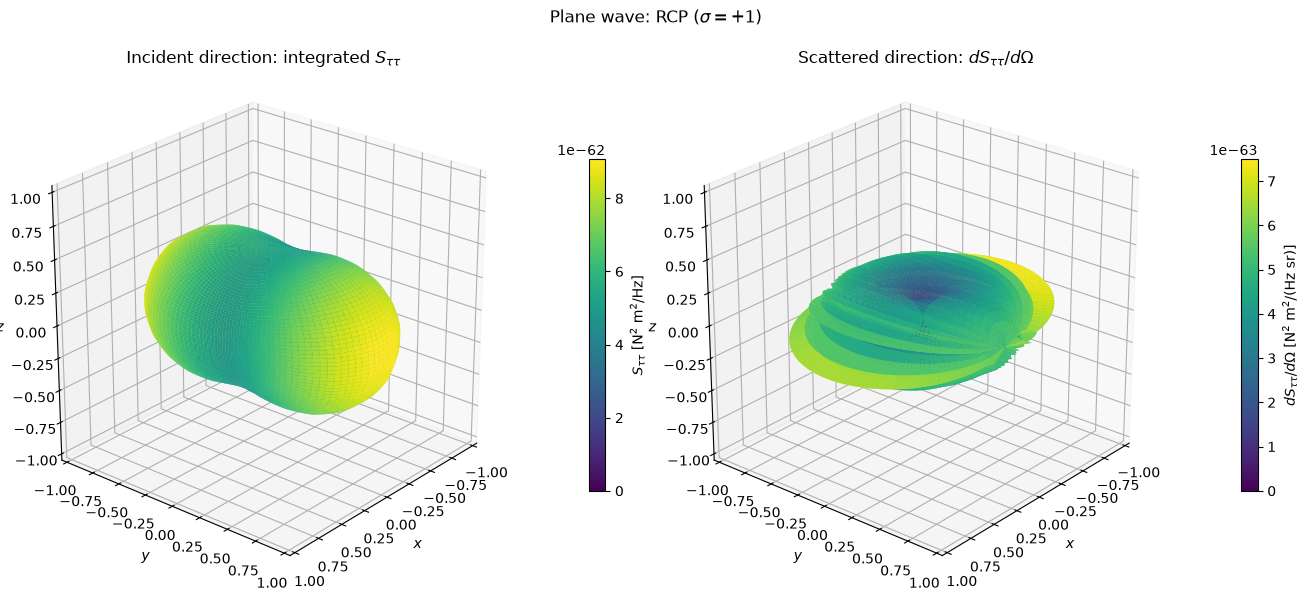

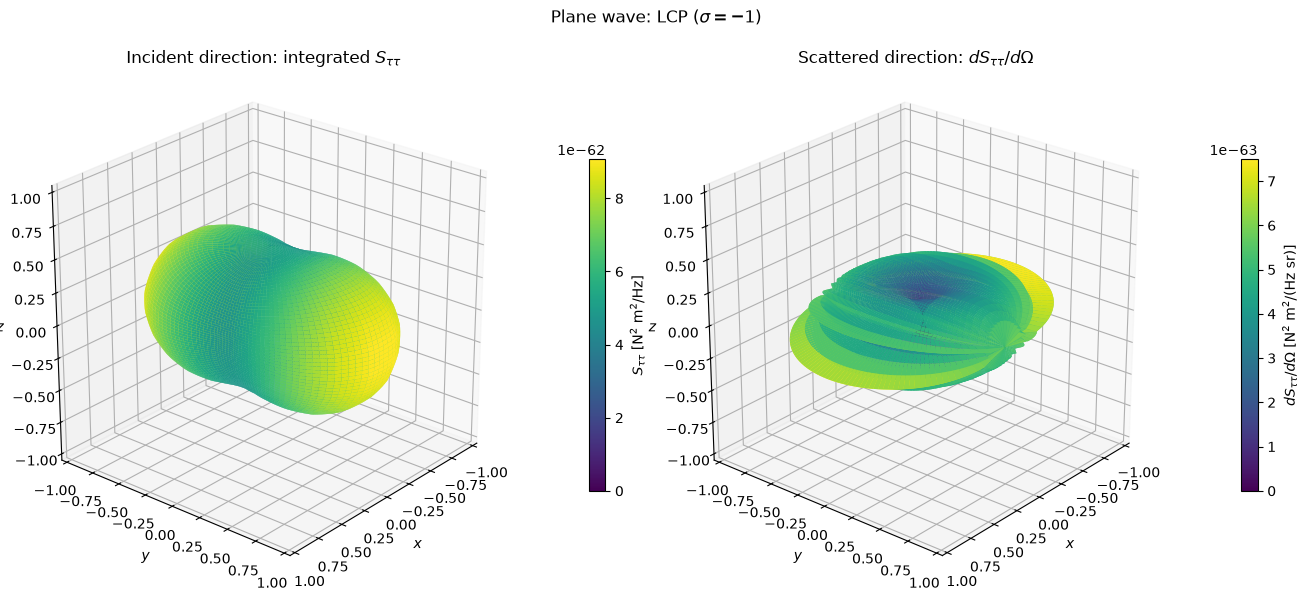

In [11]:
## PLANE-WAVE INFORMATION PATTERNS
for helicity in helicities:
    plot_pattern_pair(plane_wave_result, "Plane wave", helicity)

In [12]:
## PLANE-WAVE CSV
if SAVE_CSV:
    plane_wave_csv = save_pattern_csv(plane_wave_result, "Plane Wave Info Patterns.csv")

Saved **8768 rows** to `/iridisfs/home/sgb1u26/optomechanics-levitation/outputs/recoil_heatings_results/Plane Wave Info Patterns.csv`

## Hermite–Gauss HG$_{00}$

The focusing parameters follow the existing HG$_{00}$ scripts: NA = 0.75, focal length = 3 mm and filling factor = 1 (entrance waist $f\,\mathrm{NA}$). The field is rescaled so its intensity at the particle centre equals the configured plane-wave intensity. Circular polarization is built as $(E_x+i\sigma E_y)/\sqrt{2}$ from the two **linearly polarized** HG$_{00}$ solutions. This keeps the phase of their longitudinal fields consistent.

A single incoming angular spectrum is prepared in the beam frame and then rotated for each incidence direction. This avoids the poorly conditioned fixed-laboratory-plane Fourier decomposition for beams travelling almost transverse to $z$.

In [13]:
## HERMITE–GAUSS FIELD AND ROTATED INCOMING SPECTRUM
HG_NA = 0.75
HG_FOCAL_LENGTH_MM = 3.0
HG_FILLING_FACTOR = 1.0
HG_W0_MM = HG_FILLING_FACTOR * HG_FOCAL_LENGTH_MM * HG_NA
HG_QUADRATURE_POINTS = 24
HG_SPECTRUM_GRID = 96
HG_SPECTRUM_SPAN_WAVELENGTHS = 16.0

def hg_linear_superposition(pos, env_dict, wavelength, helicity, NA, f, w0,
                            quadrature_points, returnField="E"):
    settings = dict(kSign=+1, NA=NA, f=f, w0=w0,
                    quadrature_points=quadrature_points, returnField=returnField)
    x_field = hermite_gauss_00(pos, env_dict, wavelength, theta=0, **settings)
    y_field = hermite_gauss_00(pos, env_dict, wavelength, theta=90, **settings)
    return (x_field + 1j * helicity * y_field) / np.sqrt(2)

def hg_rotated(pos, env_dict, wavelength, beam_direction, beam_origin_nm,
               helicity, NA, f, w0, quadrature_points, returnField="E"):
    frame = beam_frame(beam_direction)
    local_positions = (np.asarray(pos) - np.asarray(beam_origin_nm)) @ frame
    local_field = hg_linear_superposition(
        local_positions, env_dict, wavelength, helicity, NA, f, w0,
        quadrature_points, returnField=returnField)
    return local_field @ frame.T

hg_field_options = dict(NA=HG_NA, f=HG_FOCAL_LENGTH_MM, w0=HG_W0_MM,
                        quadrature_points=HG_QUADRATURE_POINTS)
raw_focus = hg_linear_superposition(
    np.zeros((1, 3)), environment, wavelength, helicity=+1, **hg_field_options)[0]
HG_AMPLITUDE = E0 / np.linalg.norm(raw_focus)

def hg_parameters(direction, helicity):
    return dict(wavelength_nm=wavelength, environment=environment,
                amplitude_v_per_m=HG_AMPLITUDE, beam_direction=tuple(direction),
                beam_origin_nm=tuple(particle_center_nm), helicity=helicity,
                **hg_field_options)

def hg_local_parameters(helicity):
    return dict(wavelength_nm=wavelength, environment=environment,
                amplitude_v_per_m=HG_AMPLITUDE, helicity=helicity,
                **hg_field_options)

hg_base_spectra = {}
for helicity in helicities:
    by_axis = {
        axis: _angular_spectrum_from_field(
            hg_linear_superposition, hg_local_parameters(helicity), np.zeros(3),
            axis, HG_SPECTRUM_GRID, HG_SPECTRUM_SPAN_WAVELENGTHS)
        for axis in "xyz"
    }
    if not all(np.array_equal(by_axis["x"]["directions"], by_axis[axis]["directions"])
               and np.allclose(by_axis["x"]["amplitudes"], by_axis[axis]["amplitudes"])
               for axis in "yz"):
        raise RuntimeError("HG spectra for x, y and z use different angular samples")
    hg_base_spectra[helicity] = by_axis

def rotated_hg_spectrum(direction, helicity):
    frame = beam_frame(direction)
    local_torque_axis = frame.T @ np.array([0.0, 1.0, 0.0])
    base = hg_base_spectra[helicity]
    derivative = sum(local_torque_axis[index] * base[axis]["azimuthal_derivative"]
                     for index, axis in enumerate("xyz"))
    spectrum = base["y"]
    return {
        "directions": spectrum["directions"] @ frame.T,
        "wavevectors_nm": spectrum["wavevectors_nm"] @ frame.T,
        "origin_nm": particle_center_nm,
        "amplitudes": spectrum["amplitudes"] @ frame.T,
        "azimuthal_derivative": derivative @ frame.T,
    }

# A quick consistency check, including a beam travelling across the lab z axis.
check_positions = particle_center_nm + np.array([[0, 0, 0], [50, 0, 0], [0, 50, 0], [0, 0, 50]])
for check_direction in ((0, 0, 1), (1, 0, 0), (0, 0, -1)):
    parameters = hg_parameters(check_direction, +1)
    exact_field = evaluate_incident_field(hg_rotated, check_positions, field="E", **parameters)
    spectrum = rotated_hg_spectrum(check_direction, +1)
    reconstructed = _field_from_angular_spectrum(
        check_positions, spectrum, spectrum["amplitudes"], chunk_size=256)
    relative_error = np.linalg.norm(reconstructed - exact_field) / np.linalg.norm(exact_field)
    print(f"HG spectrum check {check_direction}: relative field error = {relative_error:.3%}")
    if relative_error > 0.01:
        raise RuntimeError("HG angular spectrum reconstruction exceeded 1%; refine its grid")

HG spectrum check (0, 0, 1): relative field error = 0.011%
HG spectrum check (1, 0, 0): relative field error = 0.011%
HG spectrum check (0, 0, -1): relative field error = 0.011%


In [14]:
## HERMITE–GAUSS ANGULAR SCAN (re-run this cell to resume an interrupted scan)
if "hg_result" not in globals() or hg_result.get("signature") != pattern_signature:
    hg_result = empty_pattern_result()
run_angular_scan(hg_result, "Hermite–Gauss HG00", hg_rotated, hg_parameters,
                 spectrum_factory=rotated_hg_spectrum)

Hermite–Gauss HG00: 100%|██████████| 578/578 [47:26<00:00,  4.92s/beam]


In [15]:
## HERMITE–GAUSS SUMMARY
show_summary(hg_result)

Directions completed: **576/576**. The reference is $S_0=S_{\mathrm{spin}}+S_{\mathrm{orbital}}$. Spin and orbital shares add to $100\%$; correlation reduction and increase are separate percentages of $S_0$, not additional shares of the total noise.

| Polarization | Mean $S_{\tau\tau}$ [$\mathrm{N}^2\mathrm{m}^2/\mathrm{Hz}$] | Spin share | Orbital share | Correlation reduction | Correlation increase | Directions in histograms |
|---|---:|---:|---:|---:|---:|---:|
| RCP ($\sigma=+1$) | $6.15 \times 10^{-62}$ | $50.01\%$ | $49.99\%$ | $94.71\%$ | $0.00\%$ | 288/288 |
| LCP ($\sigma=-1$) | $6.15 \times 10^{-62}$ | $50.01\%$ | $49.99\%$ | $94.71\%$ | $0.00\%$ | 288/288 |

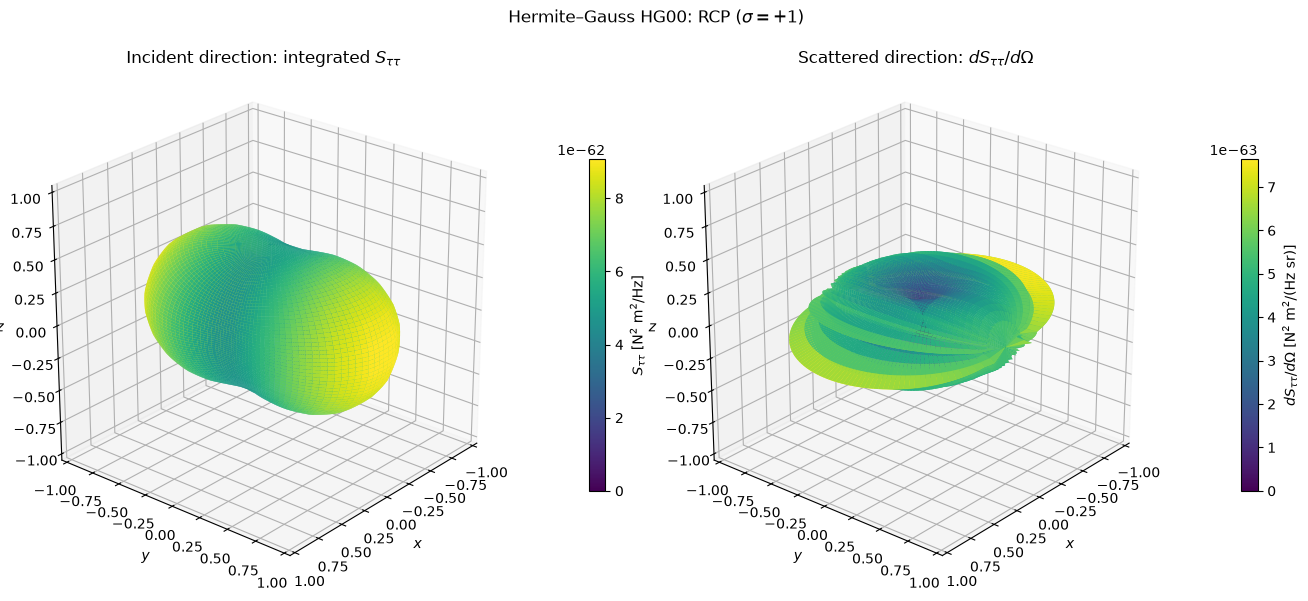

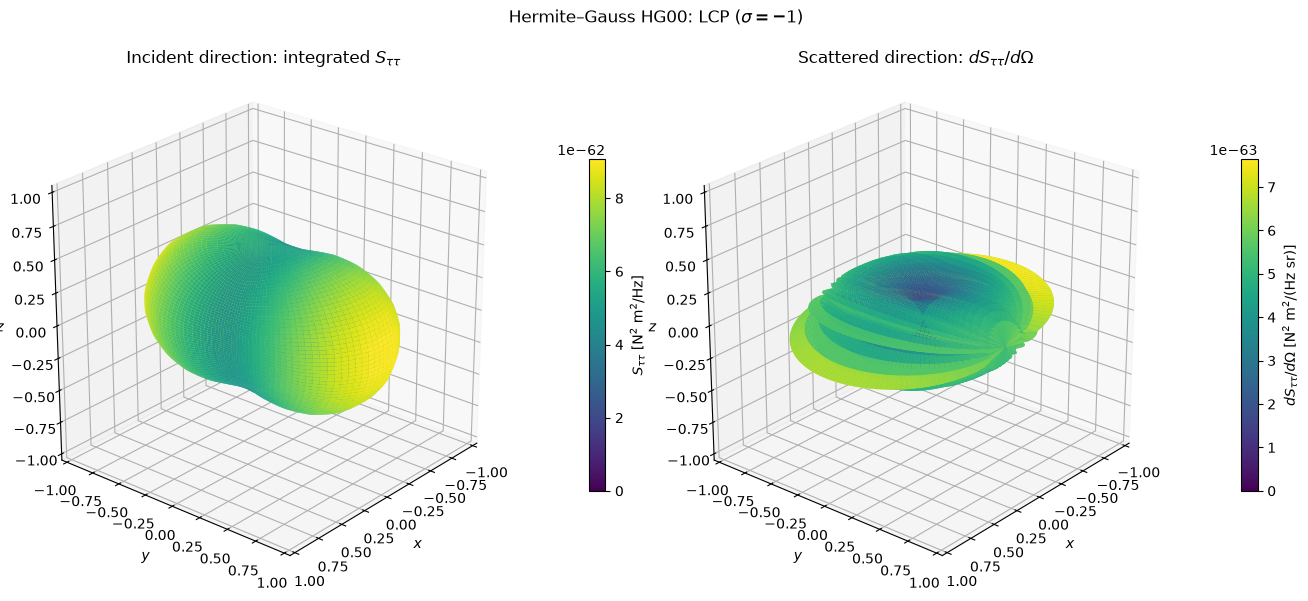

In [16]:
## HERMITE–GAUSS INFORMATION PATTERNS
for helicity in helicities:
    plot_pattern_pair(hg_result, "Hermite–Gauss HG00", helicity)

In [17]:
## HERMITE–GAUSS CSV
if SAVE_CSV:
    hg_csv = save_pattern_csv(hg_result, "Hermite-Gauss Info Patterns.csv")

Saved **8768 rows** to `/iridisfs/home/sgb1u26/optomechanics-levitation/outputs/recoil_heatings_results/Hermite-Gauss Info Patterns.csv`